# SEG301 Project — Phân loại mức độ thù ghét vùng miền Bắc/Nam

Notebook sử dụng dữ liệu **`annotations_merged_labels_en.csv`** và giữ cấu trúc thực nghiệm tương tự `SEG301_Prj.ipynb`.

Bài toán có **hai mục tiêu phân loại độc lập**:

- `north_hate`: mức độ nội dung thù ghét/hạ thấp người miền Bắc.
- `south_hate`: mức độ nội dung thù ghét/hạ thấp người miền Nam.

Mỗi mục tiêu gồm ba nhãn: `NON_HATE`, `PREJUDICIAL`, `HOSTILE`.

Quy trình: **EDA → làm sạch → chia Train/Validation/Test → TF-IDF → 3 mô hình ML → Bi-LSTM + Attention đa nhiệm → PhoBERT → so sánh → dự đoán thực tế**.


## 1. Thiết lập môi trường và cấu hình

Nếu chạy trên Google Colab, có thể bỏ dấu `#` và chạy lệnh cài đặt dưới đây trước. PhoBERT cần Internet trong lần tải mô hình đầu tiên.


In [1]:
# !pip install -q pandas numpy matplotlib seaborn scikit-learn torch transformers accelerate sentencepiece


In [2]:
import os
import random
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
LABELS = ("NON_HATE", "PREJUDICIAL", "HOSTILE")
TARGETS = ("north_hate", "south_hate")
LABEL_TO_ID = {label: idx for idx, label in enumerate(LABELS)}
ID_TO_LABEL = {idx: label for label, idx in LABEL_TO_ID.items()}

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Nhãn:", LABELS)


Thiết bị: cuda
GPU: NVIDIA GeForce RTX 5060 Ti
Nhãn: ('NON_HATE', 'PREJUDICIAL', 'HOSTILE')


## 2. Đọc và khám phá dữ liệu (EDA)

Cell dưới tự tìm CSV trong thư mục notebook, `/content` (Colab), hoặc đường dẫn gốc trên Windows.


In [3]:
DATA_NAME = "annotations_merged_labels_en.csv"
DATA_CANDIDATES = [
    Path(DATA_NAME),
    Path("/content") / DATA_NAME,
    Path(r"D:\FPTU LEARNING MATERIAL\TNMG\annotations_merged_labels_en.csv"),
]
DATA_FILE = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(
        f"Không tìm thấy {DATA_NAME}. Hãy đặt CSV cùng thư mục với notebook."
    )

raw_df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")
expected_columns = {"comment", *TARGETS}
missing_columns = expected_columns - set(raw_df.columns)
if missing_columns:
    raise ValueError(f"CSV thiếu các cột bắt buộc: {sorted(missing_columns)}")

print("Tệp dữ liệu:", DATA_FILE.resolve())
print(f"Kích thước: {raw_df.shape[0]:,} dòng × {raw_df.shape[1]} cột")
display(raw_df.head())
display(raw_df.info())
print("Số ô thiếu theo cột:")
display(raw_df.isna().sum().to_frame("missing"))


Tệp dữ liệu: D:\FPTU LEARNING MATERIAL\TNMG\annotations_merged_labels_en.csv
Kích thước: 4,423 dòng × 3 cột


,comment,north_hate,south_hate
0,không có cách mạng Miền Nam thì quân dân miền ...,NON_HATE,NON_HATE
1,Các bạn ngoài aay vài Nam làm ăn là sợ khi trở...,NON_HATE,NON_HATE
2,"cali : parky, namki/namkiki, trungki\n🧠🤏🏻",NON_HATE,NON_HATE
3,Nghe em nói miền Bắc sao giống văn hoá Trung Quốc,NON_HATE,NON_HATE
4,tính ra một chữ của miền Bắc bằng chục câu ở m...,NON_HATE,NON_HATE


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4423 entries, 0 to 4422
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   comment     4423 non-null   object
 1   north_hate  4423 non-null   object
 2   south_hate  4423 non-null   object
dtypes: object(3)
memory usage: 103.8+ KB


None

Số ô thiếu theo cột:


,missing
comment,0
north_hate,0
south_hate,0


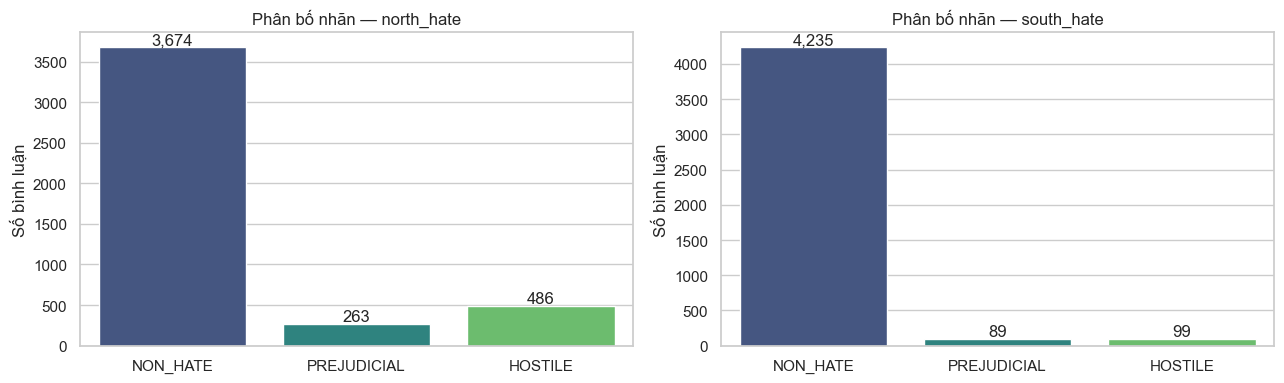

Phân bố tổ hợp hai nhãn:


count
north_hate  south_hate        
NON_HATE    NON_HATE      3501
HOSTILE     NON_HATE       474
PREJUDICIAL NON_HATE       260
NON_HATE    PREJUDICIAL     87
            HOSTILE         86
HOSTILE     HOSTILE         12
PREJUDICIAL PREJUDICIAL      2
            HOSTILE          1

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, target in zip(axes, TARGETS):
    counts = raw_df[target].value_counts().reindex(LABELS, fill_value=0)
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="viridis")
    ax.set_title(f"Phân bố nhãn — {target}")
    ax.set_xlabel("")
    ax.set_ylabel("Số bình luận")
    for i, value in enumerate(counts.values):
        ax.text(i, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print("Phân bố tổ hợp hai nhãn:")
display(
    raw_df.groupby(list(TARGETS)).size()
    .sort_values(ascending=False)
    .rename("count").to_frame()
)


## 3. Làm sạch dữ liệu

Chỉ chuẩn hóa Unicode/khoảng trắng ở mức an toàn, không xóa dấu câu hay từ phủ định vì chúng có thể mang tín hiệu thù ghét. Dòng thiếu, nhãn ngoài miền hợp lệ và bình luận trùng hoàn toàn sẽ bị loại.


In [5]:
def normalize_text(text):
    text = str(text).replace("\u200b", " ").replace("\xa0", " ")
    return re.sub(r"\s+", " ", text).strip()

work_df = raw_df[["comment", *TARGETS]].dropna().copy()
work_df["comment"] = work_df["comment"].map(normalize_text)
work_df = work_df[work_df["comment"].str.len() > 0]

valid_mask = work_df[list(TARGETS)].isin(LABELS).all(axis=1)
invalid_count = int((~valid_mask).sum())
work_df = work_df[valid_mask].copy()

before_dedup = len(work_df)
clean_df = work_df.drop_duplicates(subset=["comment"], keep="first").reset_index(drop=True)

print(f"Dòng ban đầu:                 {len(raw_df):,}")
print(f"Dòng có nhãn không hợp lệ:    {invalid_count:,}")
print(f"Dòng trùng đã loại:           {before_dedup - len(clean_df):,}")
print(f"Dòng sạch còn lại:            {len(clean_df):,}")
display(clean_df.head())


Dòng ban đầu:                 4,423
Dòng có nhãn không hợp lệ:    0
Dòng trùng đã loại:           0
Dòng sạch còn lại:            4,423


,comment,north_hate,south_hate
0,không có cách mạng Miền Nam thì quân dân miền ...,NON_HATE,NON_HATE
1,Các bạn ngoài aay vài Nam làm ăn là sợ khi trở...,NON_HATE,NON_HATE
2,"cali : parky, namki/namkiki, trungki 🧠🤏🏻",NON_HATE,NON_HATE
3,Nghe em nói miền Bắc sao giống văn hoá Trung Quốc,NON_HATE,NON_HATE
4,tính ra một chữ của miền Bắc bằng chục câu ở m...,NON_HATE,NON_HATE


## 4. Chia Train / Validation / Test (70 / 15 / 15)

Dữ liệu được phân tầng theo `north_hate` vì đây là mục tiêu có phân bố đầy đủ và ổn định nhất. Tập validation/test giữ nguyên phân bố tự nhiên. Tất cả vectorizer, trọng số lớp và từ vựng chỉ được học từ train.


In [6]:
train_val, test_df = train_test_split(
    clean_df,
    test_size=0.15,
    random_state=SEED,
    stratify=clean_df["north_hate"],
)
train_df, val_df = train_test_split(
    train_val,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val["north_hate"],
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = []
for split_name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    row = {"split": split_name, "rows": len(frame)}
    for target in TARGETS:
        for label in LABELS:
            row[f"{target}:{label}"] = int((frame[target] == label).sum())
    split_summary.append(row)
display(pd.DataFrame(split_summary))

assert set(train_df.index)  # tập train không rỗng
assert not (set(train_df["comment"]) & set(val_df["comment"]))
assert not (set(train_df["comment"]) & set(test_df["comment"]))
assert not (set(val_df["comment"]) & set(test_df["comment"]))
print("✓ Không có bình luận giao nhau giữa ba tập.")


,split,rows,north_hate:NON_HATE,north_hate:PREJUDICIAL,north_hate:HOSTILE,south_hate:NON_HATE,south_hate:PREJUDICIAL,south_hate:HOSTILE
0,Train,3095,2571,184,340,2962,60,73
1,Validation,664,551,40,73,632,15,17
2,Test,664,552,39,73,641,14,9


✓ Không có bình luận giao nhau giữa ba tập.


## 5. Lưu ba tập dữ liệu đã xử lý


In [7]:
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
for name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    output_path = PROCESSED_DIR / f"{name}.csv"
    frame.to_csv(output_path, index=False, encoding="utf-8-sig")
    print(f"Đã lưu {output_path} ({len(frame):,} dòng)")


Đã lưu data\processed\train.csv (3,095 dòng)
Đã lưu data\processed\val.csv (664 dòng)
Đã lưu data\processed\test.csv (664 dòng)


## 6. TF-IDF unigram + bigram

TF-IDF chỉ `fit` trên tập train. `min_df=2` giảm nhiễu do các token chỉ xuất hiện một lần.


In [8]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b\w+\b",
    lowercase=True,
    sublinear_tf=True,
    min_df=2,
    max_df=0.98,
    max_features=50_000,
    norm="l2",
)
X_train = vectorizer.fit_transform(train_df["comment"])
X_val = vectorizer.transform(val_df["comment"])
X_test = vectorizer.transform(test_df["comment"])

print(f"Kích thước từ vựng: {len(vectorizer.vocabulary_):,}")
print("Train/Val/Test:", X_train.shape, X_val.shape, X_test.shape)


Kích thước từ vựng: 8,174
Train/Val/Test: (3095, 8174) (664, 8174) (664, 8174)


## 7. Hàm đánh giá dùng chung

Macro-F1 là chỉ số chính vì hai mục tiêu đều mất cân bằng mạnh. Kết quả được lưu riêng cho từng mô hình, từng đầu ra và từng tập.


In [9]:
def metrics_from_predictions(y_true, y_pred, model_name, target, split):
    return {
        "model": model_name,
        "target": target,
        "split": split,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, labels=list(LABELS), average="macro", zero_division=0
        )),
        "classification_report": classification_report(
            y_true, y_pred, labels=list(LABELS), output_dict=True, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(LABELS)).tolist(),
        "predictions": np.asarray(y_pred),
    }

def print_result(result):
    print(
        f"[{result['model']} | {result['target']} | {result['split']}] "
        f"Accuracy={result['accuracy']:.4f} | Macro-F1={result['macro_f1']:.4f}"
    )

model_results = {}
trained_models = {}


## 8. Model 1 — Random Forest

Mỗi mục tiêu có một bộ phân loại riêng. `class_weight="balanced_subsample"` giúp giảm thiên lệch về `NON_HATE` mà không nhân bản validation/test.


In [10]:
rf_template = RandomForestClassifier(
    n_estimators=400,
    criterion="entropy",
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1,
)

model_name = "Random Forest"
trained_models[model_name] = {}
model_results[model_name] = {}
for target in TARGETS:
    clf = clone(rf_template).fit(X_train, train_df[target])
    trained_models[model_name][target] = clf
    model_results[model_name][target] = {
        "val": metrics_from_predictions(val_df[target], clf.predict(X_val), model_name, target, "val"),
        "test": metrics_from_predictions(test_df[target], clf.predict(X_test), model_name, target, "test"),
    }
    print_result(model_results[model_name][target]["test"])


[Random Forest | north_hate | test] Accuracy=0.8795 | Macro-F1=0.5327
[Random Forest | south_hate | test] Accuracy=0.9684 | Macro-F1=0.4492


## 9. Model 2 — Logistic Regression

Logistic Regression thường là baseline mạnh cho TF-IDF. Trọng số lớp được tính tự động từ tập train.


In [11]:
lr_template = LogisticRegression(
    solver="saga",
    max_iter=3000,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)

model_name = "Logistic Regression"
trained_models[model_name] = {}
model_results[model_name] = {}
for target in TARGETS:
    clf = clone(lr_template).fit(X_train, train_df[target])
    trained_models[model_name][target] = clf
    model_results[model_name][target] = {
        "val": metrics_from_predictions(val_df[target], clf.predict(X_val), model_name, target, "val"),
        "test": metrics_from_predictions(test_df[target], clf.predict(X_test), model_name, target, "test"),
    }
    print_result(model_results[model_name][target]["test"])


[Logistic Regression | north_hate | test] Accuracy=0.4608 | Macro-F1=0.4491
[Logistic Regression | south_hate | test] Accuracy=0.6024 | Macro-F1=0.3377


## 10. Model 3 — Multinomial Naive Bayes

Naive Bayes nhận `sample_weight` tính từ nhãn train, nhờ đó chú ý hơn tới hai lớp thiểu số.


In [12]:
nb_template = MultinomialNB(alpha=1.0)

model_name = "Multinomial NB"
trained_models[model_name] = {}
model_results[model_name] = {}
for target in TARGETS:
    clf = clone(nb_template)
    sample_weight = compute_sample_weight(class_weight="balanced", y=train_df[target])
    clf.fit(X_train, train_df[target], sample_weight=sample_weight)
    trained_models[model_name][target] = clf
    model_results[model_name][target] = {
        "val": metrics_from_predictions(val_df[target], clf.predict(X_val), model_name, target, "val"),
        "test": metrics_from_predictions(test_df[target], clf.predict(X_test), model_name, target, "test"),
    }
    print_result(model_results[model_name][target]["test"])


[Multinomial NB | north_hate | test] Accuracy=0.7033 | Macro-F1=0.5511
[Multinomial NB | south_hate | test] Accuracy=0.7771 | Macro-F1=0.3728


## 11. Model 4 — Bi-LSTM + Attention đa nhiệm

Một encoder dùng chung học biểu diễn bình luận; hai classification head dự đoán `north_hate` và `south_hate`. Loss là tổng trung bình của hai Cross-Entropy có trọng số lớp.


In [13]:
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
MAX_SEQ_LEN = 100

def tokenize(text):
    return str(text).lower().split()

def build_vocab(texts, min_freq=2):
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))
    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for token, count in counter.items():
        if count >= min_freq:
            vocab[token] = len(vocab)
    return vocab

vocab = build_vocab(train_df["comment"])

class MultiTaskTextDataset(Dataset):
    def __init__(self, frame, vocab, max_len=MAX_SEQ_LEN):
        self.items = []
        for row in frame.itertuples(index=False):
            token_ids = [vocab.get(t, vocab[UNK_TOKEN]) for t in tokenize(row.comment)][:max_len]
            token_ids += [vocab[PAD_TOKEN]] * (max_len - len(token_ids))
            labels = [LABEL_TO_ID[getattr(row, target)] for target in TARGETS]
            self.items.append((
                torch.tensor(token_ids, dtype=torch.long),
                torch.tensor(labels, dtype=torch.long),
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]

class SimpleAttention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.projection = nn.Linear(hidden_size, hidden_size)
        self.score = nn.Linear(hidden_size, 1, bias=False)

    def forward(self, sequence, mask):
        scores = self.score(torch.tanh(self.projection(sequence))).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), sequence).squeeze(1)
        return context, weights

class MultiTaskBiLSTMAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.attention = SimpleAttention(hidden_dim * 2)
        self.dropout = nn.Dropout(dropout)
        self.heads = nn.ModuleDict({
            target: nn.Linear(hidden_dim * 2, len(LABELS)) for target in TARGETS
        })

    def forward(self, token_ids):
        mask = token_ids.ne(0)
        embedded = self.dropout(self.embedding(token_ids))
        sequence, _ = self.lstm(embedded)
        context, weights = self.attention(sequence, mask)
        context = self.dropout(context)
        logits = {target: self.heads[target](context) for target in TARGETS}
        return logits, weights

print(f"Vocabulary: {len(vocab):,} tokens")


Vocabulary: 2,444 tokens


In [14]:
RUN_BILSTM = True
BILSTM_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 3

def predict_bilstm(model, loader):
    model.eval()
    predictions = {target: [] for target in TARGETS}
    true_labels = {target: [] for target in TARGETS}
    with torch.no_grad():
        for token_ids, labels in loader:
            logits, _ = model(token_ids.to(DEVICE))
            for target_idx, target in enumerate(TARGETS):
                predictions[target].extend(logits[target].argmax(-1).cpu().tolist())
                true_labels[target].extend(labels[:, target_idx].tolist())
    return predictions, true_labels

if RUN_BILSTM:
    train_loader = DataLoader(MultiTaskTextDataset(train_df, vocab), batch_size=64, shuffle=True)
    val_loader = DataLoader(MultiTaskTextDataset(val_df, vocab), batch_size=128)
    test_loader = DataLoader(MultiTaskTextDataset(test_df, vocab), batch_size=128)

    bilstm_model = MultiTaskBiLSTMAttention(len(vocab)).to(DEVICE)
    optimizer = torch.optim.AdamW(bilstm_model.parameters(), lr=1e-3, weight_decay=1e-5)
    criteria = {}
    for target in TARGETS:
        weights = compute_class_weight(
            class_weight="balanced", classes=np.array(LABELS), y=train_df[target]
        )
        criteria[target] = nn.CrossEntropyLoss(
            weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE)
        )

    best_score, best_state, stale_epochs = -1.0, None, 0
    for epoch in range(1, BILSTM_EPOCHS + 1):
        bilstm_model.train()
        running_loss = 0.0
        for token_ids, labels in train_loader:
            token_ids, labels = token_ids.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            logits, _ = bilstm_model(token_ids)
            loss = sum(
                criteria[target](logits[target], labels[:, idx])
                for idx, target in enumerate(TARGETS)
            ) / len(TARGETS)
            loss.backward()
            nn.utils.clip_grad_norm_(bilstm_model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item()

        val_pred_ids, val_true_ids = predict_bilstm(bilstm_model, val_loader)
        target_f1 = [
            f1_score(val_true_ids[t], val_pred_ids[t], average="macro", zero_division=0)
            for t in TARGETS
        ]
        mean_f1 = float(np.mean(target_f1))
        print(
            f"Epoch {epoch:02d} | loss={running_loss/len(train_loader):.4f} | "
            f"val mean Macro-F1={mean_f1:.4f}"
        )
        if mean_f1 > best_score:
            best_score = mean_f1
            best_state = {k: v.detach().cpu().clone() for k, v in bilstm_model.state_dict().items()}
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= EARLY_STOPPING_PATIENCE:
                print("Early stopping.")
                break

    bilstm_model.load_state_dict(best_state)
    bilstm_model.to(DEVICE)
    val_pred_ids, val_true_ids = predict_bilstm(bilstm_model, val_loader)
    test_pred_ids, test_true_ids = predict_bilstm(bilstm_model, test_loader)

    model_name = "Bi-LSTM + Attention"
    model_results[model_name] = {}
    for target in TARGETS:
        val_true = [ID_TO_LABEL[i] for i in val_true_ids[target]]
        val_pred = [ID_TO_LABEL[i] for i in val_pred_ids[target]]
        test_true = [ID_TO_LABEL[i] for i in test_true_ids[target]]
        test_pred = [ID_TO_LABEL[i] for i in test_pred_ids[target]]
        model_results[model_name][target] = {
            "val": metrics_from_predictions(val_true, val_pred, model_name, target, "val"),
            "test": metrics_from_predictions(test_true, test_pred, model_name, target, "test"),
        }
        print_result(model_results[model_name][target]["test"])


Epoch 01 | loss=1.0041 | val mean Macro-F1=0.4235
Epoch 02 | loss=0.8595 | val mean Macro-F1=0.4287
Epoch 03 | loss=0.7644 | val mean Macro-F1=0.4406
Epoch 04 | loss=0.6624 | val mean Macro-F1=0.4860
Epoch 05 | loss=0.5866 | val mean Macro-F1=0.4607
Epoch 06 | loss=0.4957 | val mean Macro-F1=0.4875
Epoch 07 | loss=0.4439 | val mean Macro-F1=0.5049
Epoch 08 | loss=0.3698 | val mean Macro-F1=0.5135
Epoch 09 | loss=0.3436 | val mean Macro-F1=0.5158
Epoch 10 | loss=0.2941 | val mean Macro-F1=0.5225
Epoch 11 | loss=0.2617 | val mean Macro-F1=0.5148
Epoch 12 | loss=0.2438 | val mean Macro-F1=0.5380
Epoch 13 | loss=0.1967 | val mean Macro-F1=0.5158
Epoch 14 | loss=0.1832 | val mean Macro-F1=0.5419
Epoch 15 | loss=0.1643 | val mean Macro-F1=0.5221
[Bi-LSTM + Attention | north_hate | test] Accuracy=0.7636 | Macro-F1=0.5586
[Bi-LSTM + Attention | south_hate | test] Accuracy=0.9262 | Macro-F1=0.4562


## 12. Model 5 — PhoBERT Fine-tuning

PhoBERT được fine-tune riêng cho từng mục tiêu để tận dụng trực tiếp `AutoModelForSequenceClassification`. Cell này tải mô hình khoảng vài trăm MB và chạy lâu hơn đáng kể; đặt `RUN_PHOBERT=False` nếu chỉ muốn chạy các baseline.


In [15]:
RUN_PHOBERT = True
PHOBERT_EPOCHS = 4
BASE_MODEL = "vinai/phobert-base-v2"

if RUN_PHOBERT:
    from transformers import (
        AutoModelForSequenceClassification,
        AutoTokenizer,
        DataCollatorWithPadding,
        Trainer,
        TrainingArguments,
    )

    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, use_fast=False)

    class TransformerTextDataset(Dataset):
        def __init__(self, frame, target, tokenizer, max_length=256):
            self.encodings = tokenizer(
                frame["comment"].tolist(), truncation=True, max_length=max_length
            )
            self.labels = [LABEL_TO_ID[label] for label in frame[target]]

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, idx):
            item = {key: torch.tensor(values[idx]) for key, values in self.encodings.items()}
            item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
            return item

    def compute_transformer_metrics(eval_pred):
        logits, label_ids = eval_pred
        pred_ids = np.argmax(logits, axis=-1)
        return {
            "accuracy": accuracy_score(label_ids, pred_ids),
            "macro_f1": f1_score(label_ids, pred_ids, average="macro", zero_division=0),
        }

    phobert_models = {}
    model_name = "PhoBERT Fine-Tuning"
    model_results[model_name] = {}
    for target in TARGETS:
        print(f"\n===== Fine-tuning {target} =====")
        train_ds = TransformerTextDataset(train_df, target, tokenizer)
        val_ds = TransformerTextDataset(val_df, target, tokenizer)
        test_ds = TransformerTextDataset(test_df, target, tokenizer)

        model = AutoModelForSequenceClassification.from_pretrained(
            BASE_MODEL,
            num_labels=len(LABELS),
            id2label=ID_TO_LABEL,
            label2id=LABEL_TO_ID,
        )
        args = TrainingArguments(
            output_dir=f"phobert_checkpoints/{target}",
            num_train_epochs=PHOBERT_EPOCHS,
            per_device_train_batch_size=8,
            per_device_eval_batch_size=16,
            learning_rate=2e-5,
            weight_decay=0.01,
            eval_strategy="epoch",
            save_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="macro_f1",
            greater_is_better=True,
            save_total_limit=1,
            fp16=torch.cuda.is_available(),
            seed=SEED,
            report_to="none",
        )
        trainer = Trainer(
            model=model,
            args=args,
            train_dataset=train_ds,
            eval_dataset=val_ds,
            data_collator=DataCollatorWithPadding(tokenizer),
            compute_metrics=compute_transformer_metrics,
        )
        trainer.train()
        phobert_models[target] = trainer

        val_output = trainer.predict(val_ds)
        test_output = trainer.predict(test_ds)
        val_pred = [ID_TO_LABEL[i] for i in val_output.predictions.argmax(axis=-1)]
        test_pred = [ID_TO_LABEL[i] for i in test_output.predictions.argmax(axis=-1)]
        model_results[model_name][target] = {
            "val": metrics_from_predictions(val_df[target], val_pred, model_name, target, "val"),
            "test": metrics_from_predictions(test_df[target], test_pred, model_name, target, "test"),
        }
        print_result(model_results[model_name][target]["test"])



===== Fine-tuning north_hate =====


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.379097,0.891566,0.567567
2,0.470600,0.361001,0.899096,0.577283
3,0.352000,0.363125,0.884036,0.681595
4,0.261700,0.423691,0.876506,0.682048


[PhoBERT Fine-Tuning | north_hate | test] Accuracy=0.8690 | Macro-F1=0.6861

===== Fine-tuning south_hate =====


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.234343,0.951807,0.325103
2,0.230300,0.198653,0.956325,0.479668
3,0.174700,0.202306,0.956325,0.492477
4,0.149300,0.204224,0.953313,0.501725


[PhoBERT Fine-Tuning | south_hate | test] Accuracy=0.9744 | Macro-F1=0.5956


## 13. Bảng tổng hợp kết quả

`Mean Macro-F1` là trung bình Macro-F1 của hai đầu ra Bắc/Nam. Bảng được lưu thành `model_comparison_multitask.csv`.


In [16]:
summary_rows = []
for model_name, target_results in model_results.items():
    if not all(target in target_results for target in TARGETS):
        continue
    row = {"Model": model_name}
    for split in ("val", "test"):
        for target in TARGETS:
            result = target_results[target][split]
            row[f"{split}_{target}_accuracy"] = result["accuracy"]
            row[f"{split}_{target}_macro_f1"] = result["macro_f1"]
        row[f"{split}_mean_macro_f1"] = np.mean([
            target_results[target][split]["macro_f1"] for target in TARGETS
        ])
    summary_rows.append(row)

comparison_df = (
    pd.DataFrame(summary_rows)
    .sort_values("test_mean_macro_f1", ascending=False)
    .reset_index(drop=True)
)
display(comparison_df.style.format(precision=4))
comparison_df.to_csv("model_comparison_multitask.csv", index=False, encoding="utf-8-sig")
print("Đã lưu model_comparison_multitask.csv")


,Model,val_north_hate_accuracy,val_north_hate_macro_f1,val_south_hate_accuracy,val_south_hate_macro_f1,val_mean_macro_f1,test_north_hate_accuracy,test_north_hate_macro_f1,test_south_hate_accuracy,test_south_hate_macro_f1,test_mean_macro_f1
0,PhoBERT Fine-Tuning,0.8765,0.6820,0.9533,0.5017,0.5919,0.8690,0.6861,0.9744,0.5956,0.6409
1,Bi-LSTM + Attention,0.8117,0.6202,0.9157,0.4636,0.5419,0.7636,0.5586,0.9262,0.4562,0.5074
2,Random Forest,0.8946,0.5616,0.9563,0.4797,0.5206,0.8795,0.5327,0.9684,0.4492,0.4909
3,Multinomial NB,0.7033,0.5723,0.8178,0.4403,0.5063,0.7033,0.5511,0.7771,0.3728,0.4619
4,Logistic Regression,0.4895,0.4827,0.6355,0.4286,0.4556,0.4608,0.4491,0.6024,0.3377,0.3934


Đã lưu model_comparison_multitask.csv


## 14. Trực quan hóa kết quả và ma trận nhầm lẫn


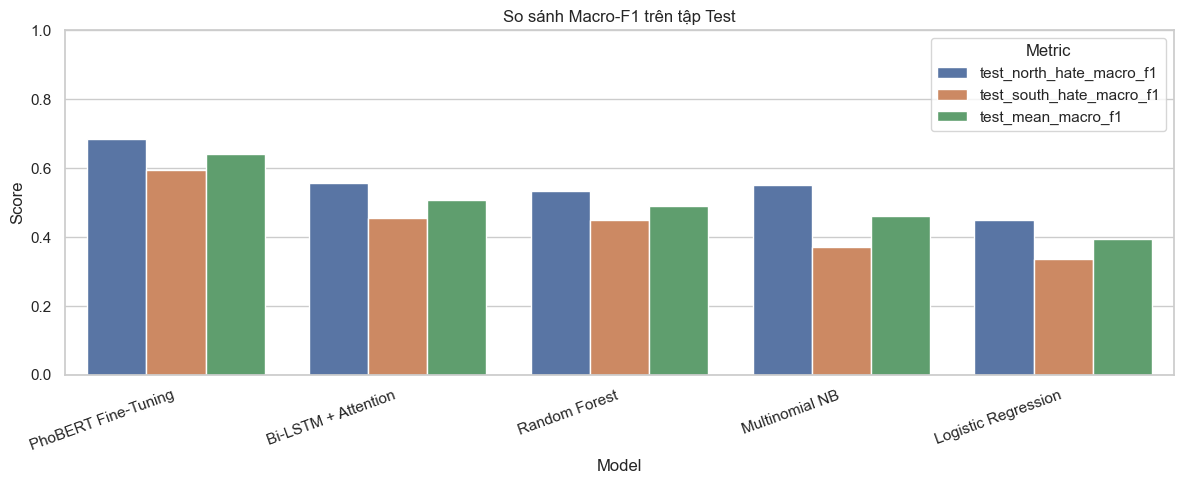

In [17]:
plot_df = comparison_df.melt(
    id_vars="Model",
    value_vars=["test_north_hate_macro_f1", "test_south_hate_macro_f1", "test_mean_macro_f1"],
    var_name="Metric",
    value_name="Score",
)
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.title("So sánh Macro-F1 trên tập Test")
plt.tight_layout()
plt.show()


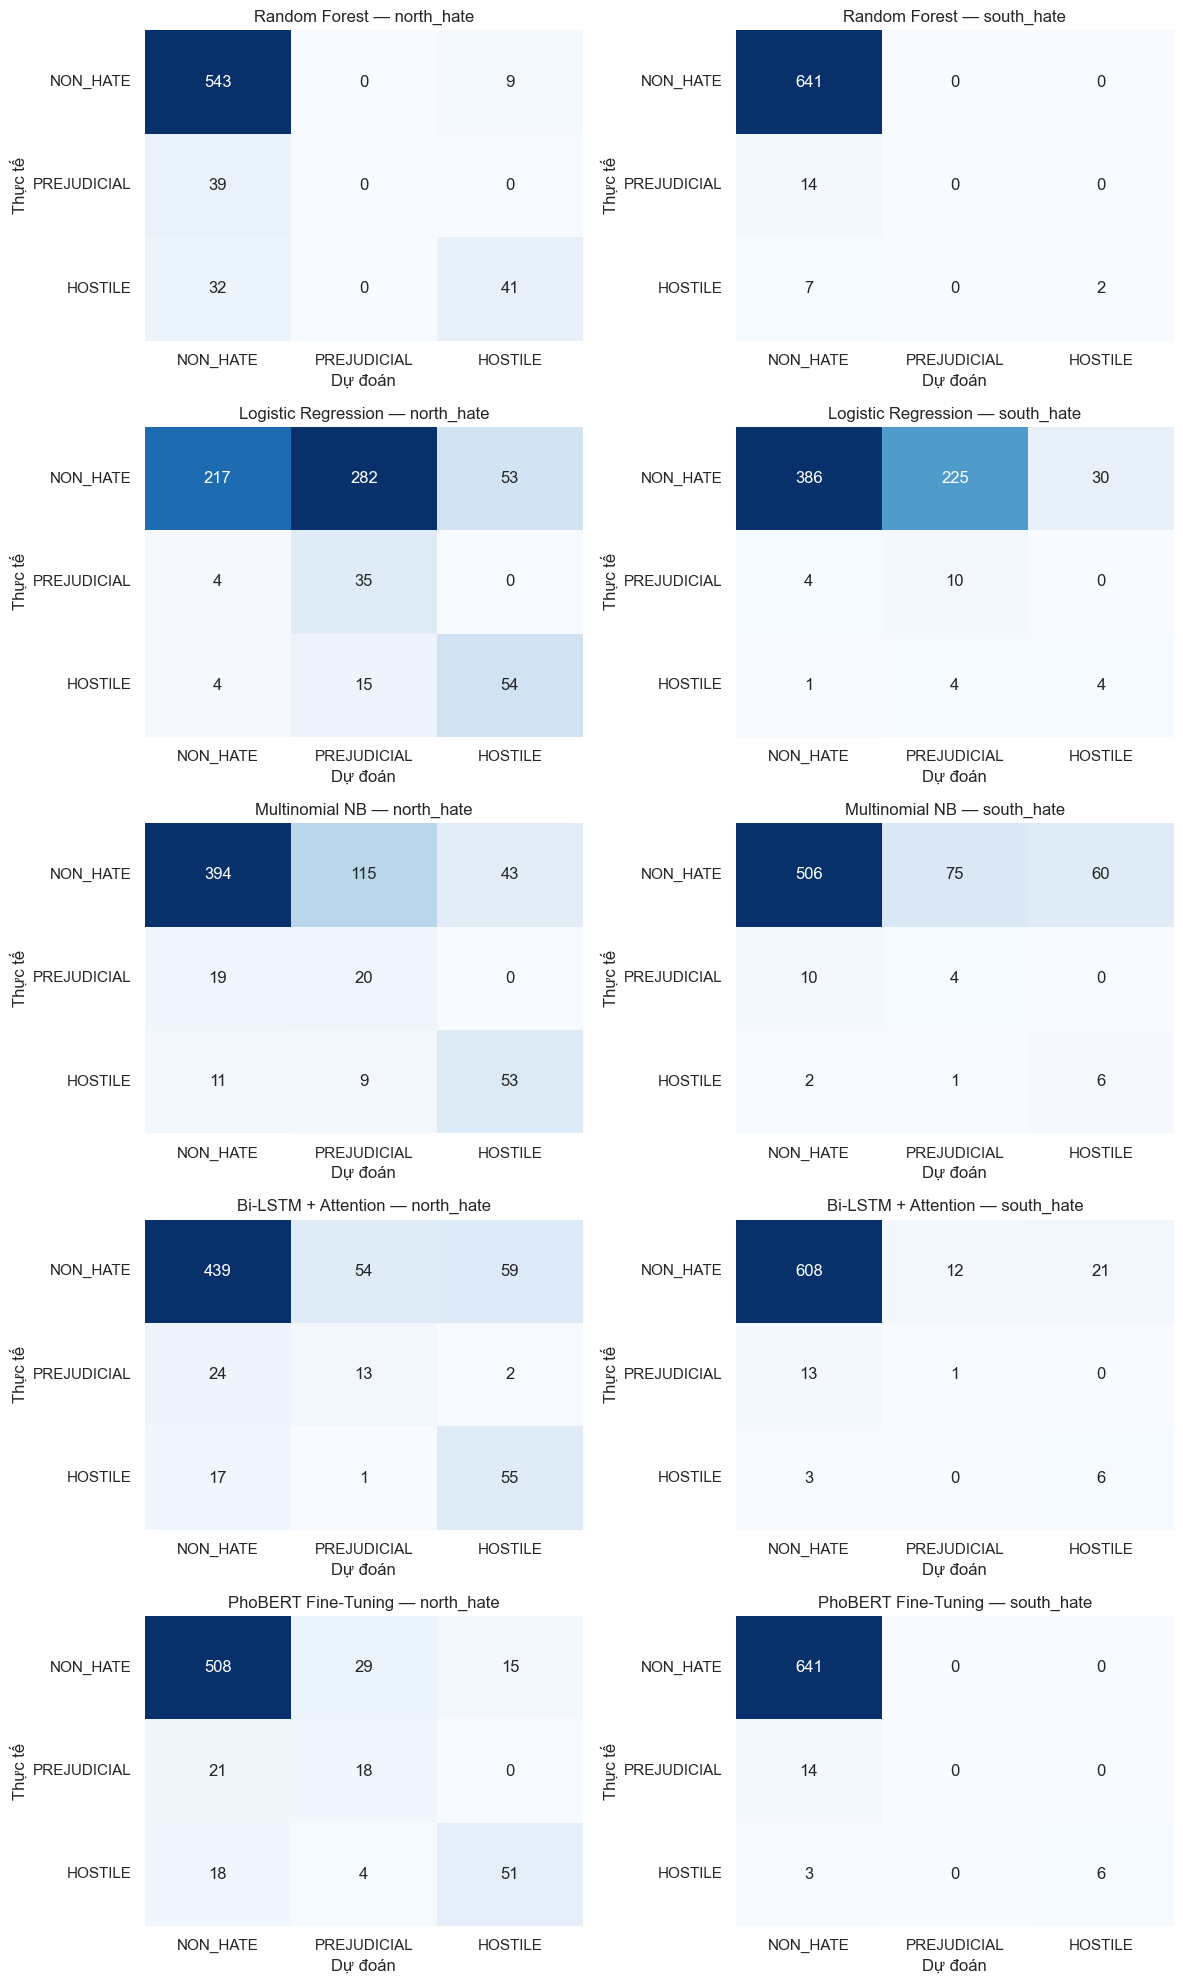

In [18]:
available = [name for name in model_results if all(t in model_results[name] for t in TARGETS)]
fig, axes = plt.subplots(len(available), len(TARGETS), figsize=(12, 4 * len(available)), squeeze=False)
for row_idx, model_name in enumerate(available):
    for col_idx, target in enumerate(TARGETS):
        cm = np.asarray(model_results[model_name][target]["test"]["confusion_matrix"])
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[row_idx, col_idx]
        )
        axes[row_idx, col_idx].set_title(f"{model_name} — {target}")
        axes[row_idx, col_idx].set_xlabel("Dự đoán")
        axes[row_idx, col_idx].set_ylabel("Thực tế")
plt.tight_layout()
plt.show()


## 15. Báo cáo chi tiết mô hình tốt nhất


In [19]:
best_model_name = comparison_df.iloc[0]["Model"]
print("Mô hình tốt nhất theo Test Mean Macro-F1:", best_model_name)
for target in TARGETS:
    print(f"\n===== {target} =====")
    report = model_results[best_model_name][target]["test"]["classification_report"]
    display(pd.DataFrame(report).T.round(4))


Mô hình tốt nhất theo Test Mean Macro-F1: PhoBERT Fine-Tuning

===== north_hate =====


,precision,recall,f1-score,support
NON_HATE,0.9287,0.9203,0.9245,552.000
PREJUDICIAL,0.3529,0.4615,0.4000,39.000
HOSTILE,0.7727,0.6986,0.7338,73.000
accuracy,0.8690,0.8690,0.8690,0.869
macro avg,0.6848,0.6935,0.6861,664.000
weighted avg,0.8777,0.8690,0.8727,664.000



===== south_hate =====


,precision,recall,f1-score,support
NON_HATE,0.9742,1.0000,0.9869,641.0000
PREJUDICIAL,0.0000,0.0000,0.0000,14.0000
HOSTILE,1.0000,0.6667,0.8000,9.0000
accuracy,0.9744,0.9744,0.9744,0.9744
macro avg,0.6581,0.5556,0.5956,664.0000
weighted avg,0.9540,0.9744,0.9636,664.0000


## 16. Dự đoán bình luận mới

Hàm trả về dự đoán cho cả `north_hate` và `south_hate`. Tham số `model_name` có thể là một trong ba baseline TF-IDF, `Bi-LSTM + Attention`, hoặc `PhoBERT Fine-Tuning` nếu đã chạy cell tương ứng.


In [20]:
def predict_comment(text, model_name="Logistic Regression"):
    text = normalize_text(text)
    if not text:
        raise ValueError("Bình luận không được rỗng.")

    output = {"comment": text, "model": model_name}
    if model_name in trained_models:
        features = vectorizer.transform([text])
        for target in TARGETS:
            clf = trained_models[model_name][target]
            pred = clf.predict(features)[0]
            prob = float(clf.predict_proba(features).max())
            output[target] = pred
            output[f"{target}_confidence"] = prob

    elif model_name == "Bi-LSTM + Attention" and "bilstm_model" in globals():
        ids = [vocab.get(t, vocab[UNK_TOKEN]) for t in tokenize(text)][:MAX_SEQ_LEN]
        ids += [vocab[PAD_TOKEN]] * (MAX_SEQ_LEN - len(ids))
        tensor = torch.tensor([ids], dtype=torch.long, device=DEVICE)
        bilstm_model.eval()
        with torch.no_grad():
            logits, _ = bilstm_model(tensor)
        for target in TARGETS:
            probabilities = torch.softmax(logits[target], dim=-1)[0].cpu().numpy()
            pred_id = int(probabilities.argmax())
            output[target] = ID_TO_LABEL[pred_id]
            output[f"{target}_confidence"] = float(probabilities[pred_id])

    elif model_name == "PhoBERT Fine-Tuning" and "phobert_models" in globals():
        for target in TARGETS:
            trainer = phobert_models[target]
            encoded = tokenizer(text, truncation=True, max_length=256, return_tensors="pt")
            device = next(trainer.model.parameters()).device
            encoded = {key: value.to(device) for key, value in encoded.items()}
            trainer.model.eval()
            with torch.no_grad():
                logits = trainer.model(**encoded).logits
            probabilities = torch.softmax(logits, dim=-1)[0].cpu().numpy()
            pred_id = int(probabilities.argmax())
            output[target] = ID_TO_LABEL[pred_id]
            output[f"{target}_confidence"] = float(probabilities[pred_id])
    else:
        raise ValueError(f"Mô hình chưa được huấn luyện hoặc không tồn tại: {model_name}")

    return pd.Series(output)

samples = [
    "Người miền nào cũng đáng được tôn trọng và đối xử công bằng.",
    "Bình luận ví dụ để kiểm tra mô hình sau khi huấn luyện.",
]
display(pd.DataFrame([predict_comment(text) for text in samples]))


,comment,model,north_hate,north_hate_confidence,south_hate,south_hate_confidence
0,Người miền nào cũng đáng được tôn trọng và đối...,Logistic Regression,PREJUDICIAL,0.793562,PREJUDICIAL,0.594732
1,Bình luận ví dụ để kiểm tra mô hình sau khi hu...,Logistic Regression,NON_HATE,0.589689,PREJUDICIAL,0.718854


## 17. Lưu các mô hình baseline để tái sử dụng

File `tfidf_baselines.joblib` chứa vectorizer, ba nhóm mô hình truyền thống và metadata nhãn. Các mô hình Deep Learning/Transformer nên lưu bằng `state_dict` hoặc `save_pretrained` sau khi đã huấn luyện.


In [21]:
import joblib

artifact = {
    "vectorizer": vectorizer,
    "models": trained_models,
    "labels": LABELS,
    "targets": TARGETS,
    "seed": SEED,
}
joblib.dump(artifact, "tfidf_baselines.joblib")
print("Đã lưu tfidf_baselines.joblib")

if "bilstm_model" in globals():
    torch.save({
        "state_dict": bilstm_model.state_dict(),
        "vocab": vocab,
        "labels": LABELS,
        "targets": TARGETS,
    }, "bilstm_attention_multitask.pt")
    print("Đã lưu bilstm_attention_multitask.pt")

if "phobert_models" in globals():
    for target, trainer in phobert_models.items():
        output_dir = Path("saved_phobert") / target
        trainer.save_model(output_dir)
        tokenizer.save_pretrained(output_dir)
        print("Đã lưu", output_dir)


Đã lưu tfidf_baselines.joblib
Đã lưu bilstm_attention_multitask.pt
Đã lưu saved_phobert\north_hate
Đã lưu saved_phobert\south_hate


## 18. Kết luận và hướng phát triển

Sau khi chạy toàn bộ notebook, dùng bảng `comparison_df` và classification report để kết luận dựa trên số liệu thực nghiệm:

1. So sánh Macro-F1 giữa baseline TF-IDF, Bi-LSTM và PhoBERT cho từng vùng.
2. Kiểm tra Recall của `PREJUDICIAL` và `HOSTILE`, không chỉ Accuracy tổng thể.
3. Xem ma trận nhầm lẫn để phát hiện mô hình có xu hướng gom lớp thiểu số về `NON_HATE` hay không.
4. Có thể cải thiện bằng repeated stratified cross-validation, focal loss, data augmentation có kiểm soát, hoặc mô hình Transformer đa nhiệm chung encoder.

> Lưu ý: không nên chọn mô hình bằng kết quả test nhiều lần. Hãy chọn theo validation, chỉ dùng test cho đánh giá cuối cùng.
